In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

FROZEN_DIR = "/content/drive/MyDrive/frozen_dataset"
PIPE_DIR = "/content/drive/MyDrive/day22/final_pipeline_v1"
TARGET_COLUMN = "soc_percent"
RAW_FEATURES = ["voltage_v", "current_a", "cell_temp_c", "power_w", "ambient_temp_c"]
os.makedirs("error_analysis", exist_ok=True)

cfg = json.load(open(f"{PIPE_DIR}/frozen_config.json"))
final_pipe = joblib.load(f"{PIPE_DIR}/soc_final_pipeline.joblib")
df_train = pd.read_csv(f"{FROZEN_DIR}/dataset_v1_train.csv")
df_test = pd.read_csv(f"{FROZEN_DIR}/dataset_v1_test.csv")

ev = df_test.copy().reset_index(drop=True)
ev["row_in_file"] = ev.groupby("file_id").cumcount()
ev["pred"] = np.clip(final_pipe.predict(ev[RAW_FEATURES]), 0, 100)
ev["err"] = ev[TARGET_COLUMN] - ev["pred"]
ev["abs"] = ev["err"].abs(); ev["sq"] = ev["err"] ** 2
ev["test_type"] = ev["file_id"].str.replace(r"^[^_]+_", "", regex=True).str.replace(r"\d+$", "", regex=True)
print("Model:", cfg["chosen_model"], "| test rows:", len(ev), "| MAE %.3f  RMSE %.3f" % (ev["abs"].mean(), np.sqrt(ev["sq"].mean())))

Model: RandomForest (tuned) | test rows: 328 | MAE 27.725  RMSE 37.708


             file_id  row_in_file  voltage_v  current_a  cell_temp_c  soc_percent     pred     err
111  25degC_C20DisCh          111      2.885      0.000       23.766        7.309  100.000 -92.691
110  25degC_C20DisCh          110      2.855      0.000       23.871        7.309   99.849 -92.540
113  25degC_C20DisCh          113      2.911      0.000       23.871        7.309   99.849 -92.540
115  25degC_C20DisCh          115      2.926      0.000       23.871        7.309   99.849 -92.540
109  25degC_C20DisCh          109      2.860     -0.153       23.871        7.780   99.849 -92.069
104  25degC_C20DisCh          104      3.117     -0.153       23.871       12.007  100.000 -87.993
119  25degC_C20DisCh          119      3.254      0.148       23.871       10.031   97.464 -87.433
103  25degC_C20DisCh          103      3.147     -0.151       23.871       12.852  100.000 -87.148
265   25degC_Charge8            1      3.222      0.000       23.976      100.000   14.046  85.954
117  25deg

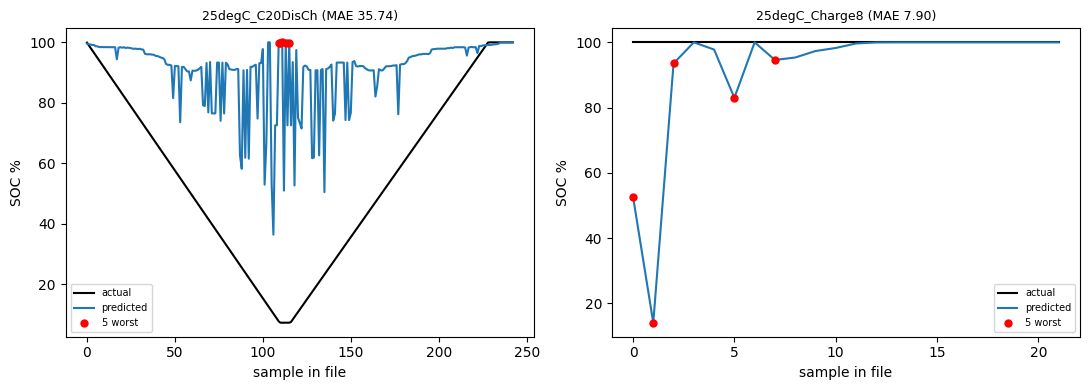

In [3]:
cols = ["file_id", "row_in_file", "voltage_v", "current_a", "cell_temp_c", TARGET_COLUMN, "pred", "err"]
worst = ev.nlargest(20, "abs")[cols]
print(worst.round(3).to_string())
worst.to_csv("error_analysis/worst_20_predictions.csv", index=False)
print("\nOver-predictions:", int((worst.err < 0).sum()), "| under-predictions:", int((worst.err > 0).sum()))
print("Worst-20 files:", worst.file_id.value_counts().to_dict())
print("Worst-20 SOC range: %.1f - %.1f | current range: %.2f - %.2f A" % (worst[TARGET_COLUMN].min(), worst[TARGET_COLUMN].max(), worst.current_a.min(), worst.current_a.max()))

top_files = ev.nlargest(20, "abs")["file_id"].value_counts().index[:3]
fig, ax = plt.subplots(1, len(top_files), figsize=(5.5 * len(top_files), 4), squeeze=False)
for a, f in zip(ax[0], top_files):
    d = ev[ev.file_id == f]
    a.plot(d.row_in_file, d[TARGET_COLUMN], "k", label="actual"); a.plot(d.row_in_file, d.pred, label="predicted")
    w = d.nlargest(5, "abs"); a.scatter(w.row_in_file, w.pred, c="red", s=25, zorder=3, label="5 worst")
    a.set_title(f"{f} (MAE {d['abs'].mean():.2f})", fontsize=9); a.set_xlabel("sample in file"); a.set_ylabel("SOC %"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("error_analysis/fig_worst_traces.png", dpi=150); plt.show()


== by SOC_band ==
               n     MAE    RMSE  bias(actual-pred)  share_of_SSE_%
SOC_band                                                           
0-15 (knee)   25  69.305  72.024            -69.305          27.808
15-30         36  60.747  62.383            -60.747          30.041
30-50         47  48.008  48.766            -48.008          23.966
50-70         48  32.505  32.910            -32.505          11.147
70-85         36  20.255  20.595            -20.255           3.274
85-100       136   4.622  11.361              1.468           3.764

== by regime ==
             n     MAE    RMSE  bias(actual-pred)  share_of_SSE_%
regime                                                           
discharge  110  36.177  42.353            -36.171          42.308
charge     153  28.237  37.403            -26.944          45.895
rest        65  12.217  29.094             -2.529          11.797

== by voltage_band ==
                 n     MAE    RMSE  bias(actual-pred)  share_of_SSE

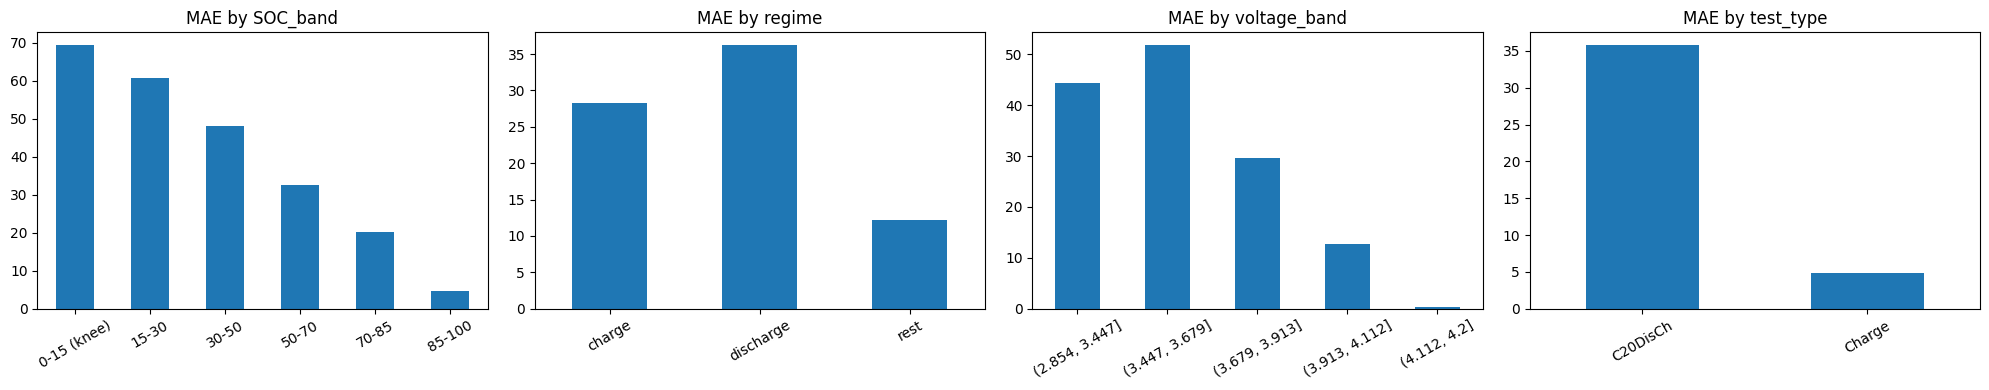


|error| percentiles 50/90/95/99/max: [24.14, 65.08, 74.8, 92.41, 92.69]
Top 1% rows carry 6% of squared error; worst file carries 97%


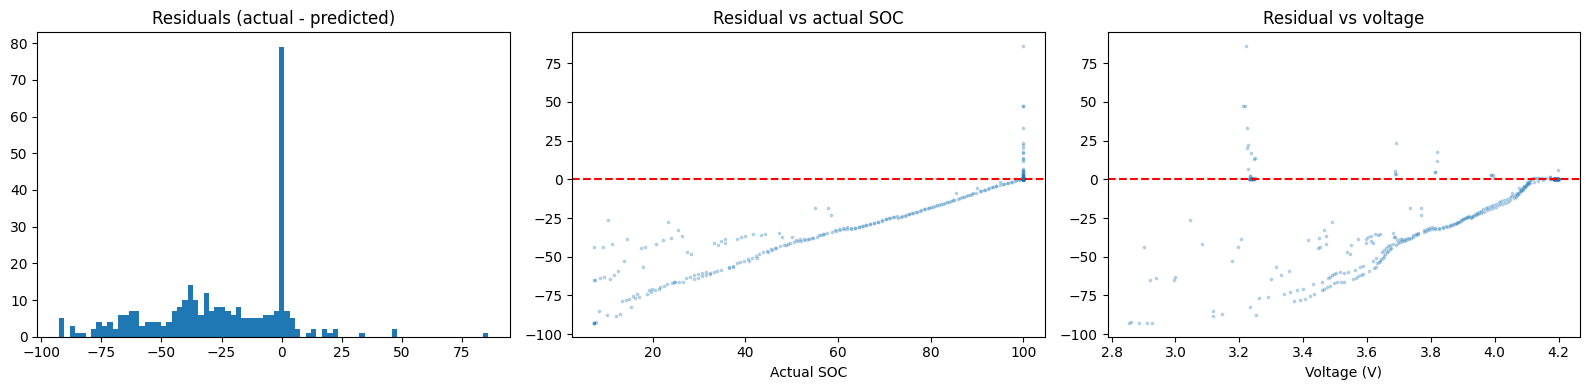

In [4]:
ev["SOC_band"] = pd.cut(ev[TARGET_COLUMN], [-0.01, 15, 30, 50, 70, 85, 100.01],
                        labels=["0-15 (knee)", "15-30", "30-50", "50-70", "70-85", "85-100"])
ev["regime"] = np.select([ev.current_a < -0.05, ev.current_a > 0.05], ["discharge", "charge"], "rest")
ev["voltage_band"] = pd.qcut(ev.voltage_v, 5, duplicates="drop").astype(str)
ev["temp_band"] = pd.qcut(ev.cell_temp_c, 4, duplicates="drop").astype(str)

total_sse = ev["sq"].sum(); tables = {}
for key in ["SOC_band", "regime", "voltage_band", "temp_band", "test_type", "file_id"]:
    g = ev.groupby(key, observed=True)
    t = pd.DataFrame({"n": g.size(), "MAE": g["abs"].mean(), "RMSE": np.sqrt(g["sq"].mean()),
                      "bias(actual-pred)": g["err"].mean(), "share_of_SSE_%": 100 * g["sq"].sum() / total_sse})
    tables[key] = t.sort_values("MAE", ascending=False)
    t.to_csv(f"error_analysis/errors_by_{key}.csv")
    print(f"\n== by {key} =="); print(tables[key].head(8).round(3).to_string())

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, k in zip(ax, ["SOC_band", "regime", "voltage_band", "test_type"]):
    tables[k]["MAE"].sort_index().plot(kind="bar", ax=a, rot=30); a.set_title(f"MAE by {k}"); a.set_xlabel("")
plt.tight_layout(); plt.savefig("error_analysis/fig_errors_by_condition.png", dpi=150); plt.show()

print("\n|error| percentiles 50/90/95/99/max:", ev["abs"].quantile([.5, .9, .95, .99, 1]).round(2).tolist())
top1 = ev.nlargest(max(1, len(ev) // 100), "sq")["sq"].sum() / total_sse
print("Top 1%% rows carry %.0f%% of squared error; worst file carries %.0f%%" % (100 * top1, 100 * ev.groupby("file_id")["sq"].sum().max() / total_sse))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(ev.err, bins=80); ax[0].set_title("Residuals (actual - predicted)")
ax[1].scatter(ev[TARGET_COLUMN], ev.err, s=3, alpha=.25); ax[1].axhline(0, c="r", ls="--"); ax[1].set_xlabel("Actual SOC"); ax[1].set_title("Residual vs actual SOC")
ax[2].scatter(ev.voltage_v, ev.err, s=3, alpha=.25); ax[2].axhline(0, c="r", ls="--"); ax[2].set_xlabel("Voltage (V)"); ax[2].set_title("Residual vs voltage")
plt.tight_layout(); plt.savefig("error_analysis/fig_residual_structure.png", dpi=150); plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


                native_importance  perm_MAE_increase  perm_std  corr_with_abs_error
voltage_v                  0.8039             4.6536    0.3205              -0.6876
current_a                  0.0091             0.5423    0.0186              -0.2348
cell_temp_c                0.1735             0.0049    0.2159              -0.1685
power_w                    0.0134             0.2088    0.0219              -0.2381
ambient_temp_c             0.0000            -0.0000    0.0000                  NaN


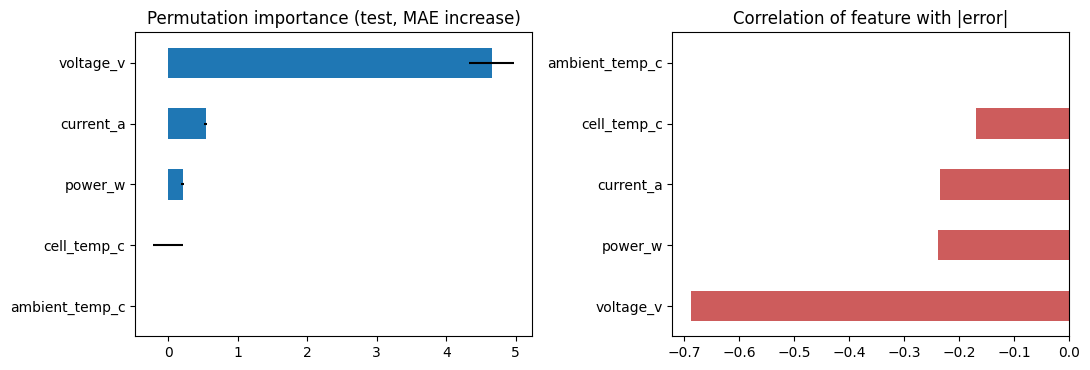

Most important feature: voltage_v - power_w = V*I, so V / I / P importance is shared (collinearity).


In [5]:
model = final_pipe.named_steps["model"]
imp = pd.DataFrame(index=RAW_FEATURES)
if hasattr(model, "feature_importances_"): imp["native_importance"] = model.feature_importances_
if hasattr(model, "coef_"): imp["linear_coef"] = model.coef_
sub = ev.sample(min(5000, len(ev)), random_state=42)
pi = permutation_importance(final_pipe, sub[RAW_FEATURES], sub[TARGET_COLUMN], scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
imp["perm_MAE_increase"] = pi.importances_mean
imp["perm_std"] = pi.importances_std
imp["corr_with_abs_error"] = [ev[f].corr(ev["abs"]) for f in RAW_FEATURES]
print(imp.round(4).to_string())
imp.to_csv("error_analysis/feature_importance.csv")

order = imp["perm_MAE_increase"].sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
imp.loc[order, "perm_MAE_increase"].plot(kind="barh", ax=ax[0], xerr=imp.loc[order, "perm_std"]); ax[0].set_title("Permutation importance (test, MAE increase)")
imp["corr_with_abs_error"].sort_values().plot(kind="barh", ax=ax[1], color="indianred"); ax[1].set_title("Correlation of feature with |error|")
plt.tight_layout(); plt.savefig("error_analysis/fig_feature_importance.png", dpi=150); plt.show()
print("Most important feature:", imp["perm_MAE_increase"].idxmax(), "- power_w = V*I, so V / I / P importance is shared (collinearity).")

In [6]:
lo, hi = df_train[RAW_FEATURES].quantile(0.01), df_train[RAW_FEATURES].quantile(0.99)
ev["outside_train_range"] = ((ev[RAW_FEATURES] < lo) | (ev[RAW_FEATURES] > hi)).any(axis=1)
ood = ev.groupby("outside_train_range")["abs"].agg(n="size", MAE="mean", max="max")
print(ood.round(3).to_string())
print("\n% test rows outside train 1-99% range per feature:",
      {f: round(float(((ev[f] < lo[f]) | (ev[f] > hi[f])).mean() * 100), 1) for f in RAW_FEATURES})
ood.to_csv("error_analysis/error_vs_input_range.csv")

                       n     MAE     max
outside_train_range                     
False                302  26.893  87.993
True                  26  37.395  92.691

% test rows outside train 1-99% range per feature: {'voltage_v': 2.7, 'current_a': 0.0, 'cell_temp_c': 5.2, 'power_w': 0.0, 'ambient_temp_c': 0.0}


In [8]:
worst_band, worst_reg = tables["SOC_band"].index[0], tables["regime"].index[0]
worst_type, worst_file = tables["test_type"].index[0], tables["file_id"].index[0]
m_in, m_out = ood["MAE"].get(False, np.nan), ood["MAE"].get(True, np.nan)

lim = f"""Limitation list - Day 25(model: {cfg['chosen_model']})
Data-driven findings (test files):
1. Worst SOC band: {worst_band} (MAE {tables['SOC_band'].iloc[0]['MAE']:.2f}); worst current regime: {worst_reg} (MAE {tables['regime'].iloc[0]['MAE']:.2f}); worst test type: {worst_type}; worst file: {worst_file} ({tables['file_id'].iloc[0]['share_of_SSE_%']:.0f}% of total squared error).
2. Heavy-tailed errors: median |err| {ev['abs'].median():.2f}, 99th pct {ev['abs'].quantile(.99):.2f}, max {ev['abs'].max():.2f}; RMSE/MAE = {np.sqrt(ev['sq'].mean())/ev['abs'].mean():.2f}.
3. Rows with inputs outside the training 1-99% range: MAE {m_out:.2f} vs {m_in:.2f} inside.
4. Dominant feature (permutation): {imp['perm_MAE_increase'].idxmax()}; V, I and P=V*I are collinear so their importances are not separable.
Structural limitations:
5. Single ambient temperature (25 C) - no evidence for -20..40 C.
6. Single-sample model: no history/temporal state, no aging term; identical V/I/T can map to different SOC.
7. Steep voltage knee near 0-15% SOC makes SOC hypersensitive to voltage noise.
8. Engineered lag/rolling features degraded accuracy (MAE ~23) - feature pipeline not trustworthy yet.
9. Remaining-charging-time model is low confidence (one CC-CV segment per file, few files).
10. Few test files; single LG HG2 cell; metrics may move under a different file-level split.
Likely failure conditions: SOC < 15%, high-current transients (US06/LA92-type drives), inputs outside the training range, sensor drift/offset, other cell chemistries.
"""
print(lim)
open("error_analysis/limitation_list.txt", "w").write(lim)

import shutil
shutil.copytree("error_analysis", "/content/drive/MyDrive/day25/error_analysis", dirs_exist_ok=True)
print(" Saved:", sorted(os.listdir("error_analysis")))

Limitation list - Day 25(model: RandomForest (tuned))
Data-driven findings (test files):
1. Worst SOC band: 0-15 (knee) (MAE 69.30); worst current regime: discharge (MAE 36.18); worst test type: C20DisCh; worst file: 25degC_C20DisCh (97% of total squared error).
2. Heavy-tailed errors: median |err| 24.14, 99th pct 92.41, max 92.69; RMSE/MAE = 1.36.
3. Rows with inputs outside the training 1-99% range: MAE 37.39 vs 26.89 inside.
4. Dominant feature (permutation): voltage_v; V, I and P=V*I are collinear so their importances are not separable.
Structural limitations:
5. Single ambient temperature (25 C) - no evidence for -20..40 C.
6. Single-sample model: no history/temporal state, no aging term; identical V/I/T can map to different SOC.
7. Steep voltage knee near 0-15% SOC makes SOC hypersensitive to voltage noise.
8. Engineered lag/rolling features degraded accuracy (MAE ~23) - feature pipeline not trustworthy yet.
9. Remaining-charging-time model is low confidence (one CC-CV segment pe